# Exercise 2: Sinusoids and the DFT

This exercise builds intuition for the main operations behind the Discrete Fourier Transform (DFT). It has five parts:
1. Generate a real sinusoid
2. Generate a complex sinusoid
3. Implement the DFT
4. Implement the IDFT
5. Compute the magnitude spectrum of a sequence

### Relevant concepts

A real sinusoid in discrete time can be written as:

\begin{equation}
x[n] = A\cos(2 \pi fnT + \varphi)
\end{equation}

where $x$ is a real-valued sequence, $n$ is the time index, $A$ is amplitude, $f$ is frequency in Hz, $T = 1/fs$ is the sampling period, $fs$ is sampling frequency in Hz, and $\varphi$ is initial phase in radians.

A complex sinusoid in discrete time can be written as:

\begin{equation}
\bar{x}[n] = Ae^{j(\omega nT + \varphi)} = A\cos(\omega nT + \varphi) + jA\sin(\omega nT + \varphi)
\end{equation}

where $\omega = 2\pi f$ is angular frequency in radians/second.

The $N$-point DFT of a sequence $x$ is:

\begin{equation}
X[k] = \sum_{n=0}^{N-1} x[n]e^{-j2\pi kn/N}, \quad k=0,\ldots,N-1
\end{equation}

The IDFT of a spectrum $X$ is:

\begin{equation}
x[n] = \frac{1}{N}\sum_{k=0}^{N-1} X[k]e^{j2\pi kn/N}, \quad n=0,\ldots,N-1
\end{equation}

The magnitude spectrum is the absolute value of the complex spectrum: $|X[k]|$.

## Part 1 – Generate a real sinusoid

The function `gen_sine()` should generate a real sinusoid (using `np.cos`) from:
- amplitude `A`
- frequency `f` (Hz)
- initial phase `phi` (radians)
- sampling rate `fs` (Hz)
- duration `t` (seconds)

Assume `A > 0`, `t > 0`, `fs > 0`, and `fs > 2f` to avoid aliasing.

Return a NumPy array `x` containing the generated sinusoid samples.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import IPython.display as ipd

In [ ]:
# E2 - 1.1: Complete function gen_sine()

def gen_sine(A, f, phi, fs, t):
    """Generate a real sinusoid from amplitude, frequency, phase, sampling rate, and duration.

    Args:
        A (float): amplitude of the sinusoid
        f (float): frequency in Hz
        phi (float): initial phase in radians
        fs (float): sampling rate in Hz
        t (float): duration in seconds

    Returns:
        np.array: generated sinusoid samples
    """
    ### Your code here
    
    # n = 0, ... N 
    N = np.round(t * fs)
    n_list = [n* (1/fs) for n in range(0, N)]

    amp_list = [A * np.cos(2*np.pi*f*n + phi) for n in n_list]
    amp_array = np.array(amp_list)
    return amp_array
    # A*np.cos(2*np.pi*f*(1/fs)*n + phi) 

In [7]:
gen_sine(A=1.0, f=10.0, phi=1.0, fs=50, t=0.1)

array([ 0.54030231, -0.63332387, -0.93171798,  0.05749049,  0.96724906])

In [17]:
test_0 = gen_sine(A=1.0, f=10.0, phi=0, fs=50, t=0.1)
test_pi_2 = gen_sine(A=1.0, f=10.0, phi=np.pi/2, fs=50, t=0.1)

print(np.min(test_0), np.min(test_pi_2))
print(np.max(test_0),np.max(test_pi_2))

-0.8090169943749476 -0.9510565162951535
1.0 0.9510565162951536


If you call `gen_sine()` with `A=1.0`, `f=10.0`, `phi=1.0`, `fs=50`, and `t=0.1`, the output should be:

```
array([ 0.54030231, -0.63332387, -0.93171798,  0.05749049,  0.96724906])
```

To hear a sinusoid, use a longer duration and higher sampling rate. For example: `A=1.0`, `f=440.0`, `phi=1.0`, `fs=5000`, `t=0.5`, then play it with:

`ipd.display(ipd.Audio(data=x, rate=fs))`

In [8]:
# E2 - 1.2: Call gen_sine() with the values above, then plot and play the output sinusoid

### Your code here
x = gen_sine(A=1.0, f=440.0, phi=1.0, fs=5000, t=0.5)
ipd.display(ipd.Audio(data=x, rate=5000))



**E2 - 1.3: Conceptual questions (answer here)**
1. Set `phi=0` and then `phi=pi/2` with the same `A`, `f`, `fs`, and `t`. How does the waveform change in time? Explain using the cosine equation.
2. Try `f=20 Hz` and `f=30 Hz` at `fs=50 Hz`. Which one violates Nyquist, and what do you observe in the plotted signal?

In [18]:
# 1. in phi = 0 de max of amplitud is in time 0 and with phase pi/2 has a displacement of a quarter of period to the right being 0 the beginning of the wave at time 0
# 

In [ ]:
# f = 30 and fs= 50 Hz violates nyquist frequency that is fs / 2 (at least two points for representing the plot). It appears aliasing 50 - 30 = 20 Hz the new frequency and 50-50 = 0hz new frequency = no frequency      


In [20]:
# comment to AI: plot it

---
## Part 1 – Corrections / Correcciones

### E2 - 1.1 `gen_sine()`

**🇬🇧 English**

Your function returns the right values for the example call (`t=0.1`), but it has these problems:

1. **The duration `t` is ignored.** `N = int(0.1 * fs)` hardcodes 0.1 s, so the call in 1.2 with `t=0.5` only produced 0.1 s of audio (500 samples instead of 2500). It should be `N = int(np.round(t * fs))`.
2. **`int()` truncates.** Because of floating-point error, `0.29 * 100 = 28.999999999999996`, and `int()` gives `28` instead of `29`. Rounding first (`np.round`) avoids this.
3. **Confusing variable name.** `n_list` holds *times* `nT` in seconds, not sample indices `n`. That's mathematically fine, but calling it `n` makes the code harder to read.
4. **Use NumPy instead of Python lists.** `np.arange` plus a vectorised `np.cos` is shorter, much faster, and returns an array directly.

**🇪🇸 Español**

Tu función devuelve los valores correctos para la llamada de ejemplo (`t=0.1`), pero tiene estos problemas:

1. **Se ignora la duración `t`.** `N = int(0.1 * fs)` fija 0.1 s, así que la llamada de 1.2 con `t=0.5` solo generó 0.1 s de audio (500 muestras en vez de 2500). Debe ser `N = int(np.round(t * fs))`.
2. **`int()` trunca.** Por el error de coma flotante, `0.29 * 100 = 28.999999999999996` e `int()` da `28` en vez de `29`. Redondear antes (`np.round`) lo evita.
3. **Nombre de variable confuso.** `n_list` contiene *tiempos* `nT` en segundos, no índices de muestra `n`. Matemáticamente es correcto, pero llamarlo `n` dificulta la lectura.
4. **Usa NumPy en lugar de listas de Python.** `np.arange` con `np.cos` vectorizado es más corto, mucho más rápido y devuelve directamente un array.

In [23]:
# E2 - 1.1 (corrected / corregido)

def gen_sine(A, f, phi, fs, t):
    """Generate a real sinusoid from amplitude, frequency, phase, sampling rate, and duration."""
    N = int(np.round(t * fs))       # number of samples / número de muestras
    n = np.arange(N)                # sample indices 0..N-1 / índices de muestra
    return A * np.cos(2 * np.pi * f * n / fs + phi)   # x[n] = A cos(2π f n T + φ), T = 1/fs

print(gen_sine(A=1.0, f=10.0, phi=1.0, fs=50, t=0.1))
# expected / esperado: [ 0.54030231 -0.63332387 -0.93171798  0.05749049  0.96724906]

[ 0.54030231 -0.63332387 -0.93171798  0.05749049  0.96724906]


### E2 - 1.2 Plot and play / Gráfica y audio

**🇬🇧** The plot was missing, and `rate=5000` was hardcoded in `ipd.Audio`. Keep `fs` in a variable and reuse it. 0.5 s at 440 Hz is 220 periods, which is too dense to see, so plot only the first few milliseconds.

**🇪🇸** Faltaba la gráfica, y `rate=5000` estaba escrito a mano en `ipd.Audio`. Guarda `fs` en una variable y reutilízala. 0.5 s a 440 Hz son 220 periodos, demasiado denso para verlo, así que dibuja solo los primeros milisegundos.

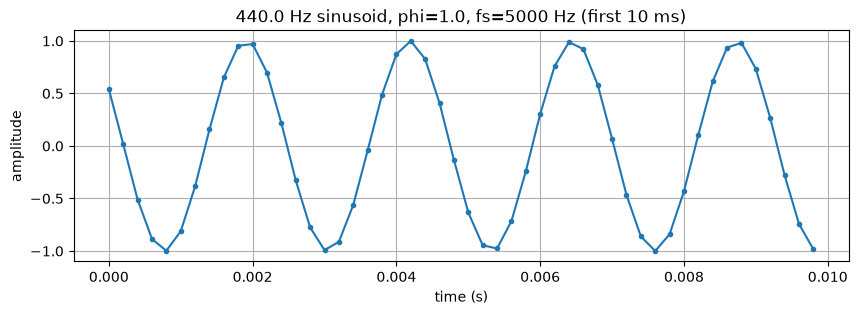

In [24]:
# E2 - 1.2 (corrected / corregido)

A, f, phi, fs, t = 1.0, 440.0, 1.0, 5000, 0.5
x = gen_sine(A, f, phi, fs, t)
time = np.arange(x.size) / fs

plt.figure(figsize=(10, 3))
n_show = int(0.01 * fs)   # first 10 ms / primeros 10 ms
plt.plot(time[:n_show], x[:n_show], '-o', markersize=3)
plt.xlabel('time (s)')
plt.ylabel('amplitude')
plt.title(f'{f} Hz sinusoid, phi={phi}, fs={fs} Hz (first 10 ms)')
plt.grid(True)
plt.show()

ipd.display(ipd.Audio(data=x, rate=fs))

### E2 - 1.3 Conceptual questions / Preguntas conceptuales

**Question 1 – `phi=0` vs `phi=pi/2`**

**🇬🇧** You were right that the shift is a quarter of a period, but **the direction is wrong: a positive phase shifts the wave to the *left* (it advances it), not to the right.**

$$A\cos(2\pi f nT + \tfrac{\pi}{2}) = A\cos\!\big(2\pi f (nT + \tfrac{1}{4f})\big) = -A\sin(2\pi f nT)$$

The waveform with `phi=pi/2` is the `phi=0` waveform moved $\frac{1}{4f}$ seconds earlier (for `f=10` Hz, that's 0.025 s to the left). At $n=0$ the cosine starts at its maximum ($A$), while with $\varphi=\pi/2$ it starts at $0$ and goes **down** (it is $-\sin$). In general, $\cos(\omega t + \varphi)$ has a time shift of $-\varphi/\omega$.

Your `min`/`max` test also shows a sampling effect: with `fs=50` and `f=10` there are only 5 samples per period. With `phi=pi/2` no sample falls exactly on a peak, so the maximum is 0.951 instead of 1. The underlying continuous signal still has amplitude 1.

**🇪🇸** Acertaste en que el desplazamiento es de un cuarto de periodo, pero **la dirección es incorrecta: una fase positiva desplaza la onda hacia la *izquierda* (la adelanta), no hacia la derecha.**

La onda con `phi=pi/2` es la de `phi=0` adelantada $\frac{1}{4f}$ segundos (para `f=10` Hz, 0.025 s hacia la izquierda). En $n=0$ el coseno empieza en su máximo ($A$), mientras que con $\varphi=\pi/2$ empieza en $0$ y **baja** (es $-\sin$). En general, $\cos(\omega t + \varphi)$ tiene un desplazamiento temporal de $-\varphi/\omega$.

Tu prueba de `min`/`max` también muestra un efecto del muestreo: con `fs=50` y `f=10` solo hay 5 muestras por periodo. Con `phi=pi/2` ninguna muestra cae justo en un pico, así que el máximo es 0.951 en vez de 1. La señal continua subyacente sigue teniendo amplitud 1.

---

**Question 2 – `f=20` vs `f=30` at `fs=50`**

**🇬🇧** In your answer you mixed up *frequency* and *sampling rate*: the question keeps **`fs = 50` Hz fixed** and changes **`f`** to 20 and 30 Hz. The "50 − 50 = 0 Hz" case doesn't apply here.

- Nyquist frequency: $f_s/2 = 25$ Hz. You need **more than** 2 samples per period, strictly ($f < f_s/2$).
- **`f = 20` Hz** is below 25 Hz, so it's OK (2.5 samples per period).
- **`f = 30` Hz** is above 25 Hz, so it **violates Nyquist** and aliases to $|30 - 50| = 20$ Hz.

Proof: $\cos(2\pi \cdot 30\, n/50) = \cos(2\pi \cdot 30\, n/50 - 2\pi n) = \cos(2\pi(-20)\,n/50) = \cos(2\pi \cdot 20\, n/50)$.

So with `phi=0` the samples of the 30 Hz and 20 Hz sinusoids are **exactly identical**; once sampled, they can't be told apart. With a nonzero phase, the alias also flips the sign of the phase: 30 Hz with $\varphi$ equals 20 Hz with $-\varphi$.

**🇪🇸** En tu respuesta confundiste *frecuencia* con *frecuencia de muestreo*: la pregunta mantiene **`fs = 50` Hz fija** y cambia **`f`** a 20 y 30 Hz. El caso "50 − 50 = 0 Hz" no aplica aquí.

- Frecuencia de Nyquist: $f_s/2 = 25$ Hz. Se necesitan **más de** 2 muestras por periodo, estrictamente ($f < f_s/2$).
- **`f = 20` Hz** está por debajo de 25 Hz, así que es correcto (2.5 muestras por periodo).
- **`f = 30` Hz** está por encima de 25 Hz, así que **viola Nyquist** y produce alias en $|30 - 50| = 20$ Hz.

Demostración: $\cos(2\pi \cdot 30\, n/50) = \cos(2\pi \cdot 30\, n/50 - 2\pi n) = \cos(2\pi(-20)\,n/50) = \cos(2\pi \cdot 20\, n/50)$.

Así, con `phi=0` las muestras de las sinusoides de 30 Hz y 20 Hz son **exactamente iguales**; una vez muestreadas no se pueden distinguir. Con fase distinta de cero, el alias además invierte el signo de la fase: 30 Hz con $\varphi$ equivale a 20 Hz con $-\varphi$.

The plots below show both effects / Las gráficas de abajo muestran ambos efectos.

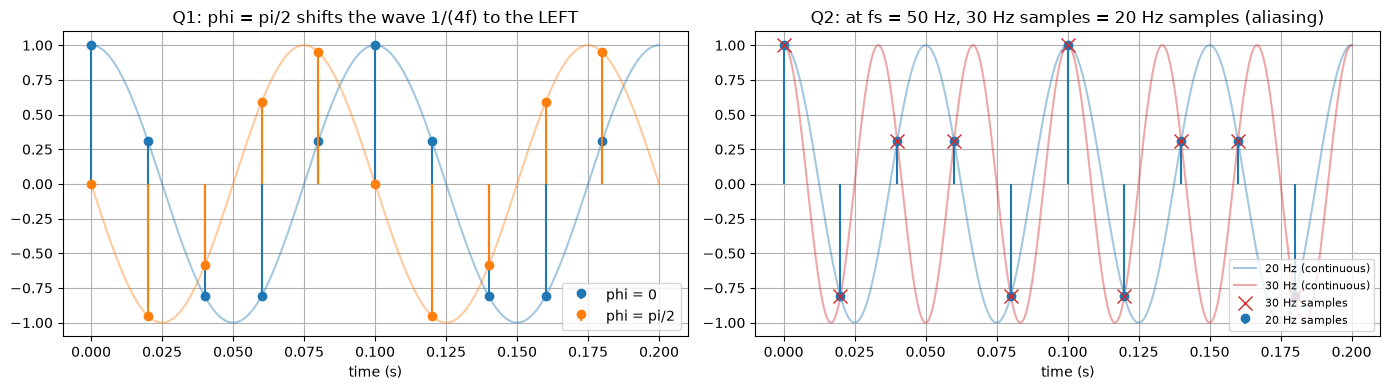

30 Hz and 20 Hz samples identical: True


In [25]:
# E2 - 1.3 plots / gráficas

fs, t = 50, 0.2
n = np.arange(int(np.round(t * fs)))
t_cont = np.linspace(0, t, 2000)   # "continuous" time for reference / tiempo "continuo" de referencia

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Q1: phase shift / desplazamiento de fase (f = 10 Hz)
f = 10
for phi, c, lbl in [(0, 'C0', 'phi = 0'), (np.pi/2, 'C1', 'phi = pi/2')]:
    axes[0].plot(t_cont, np.cos(2*np.pi*f*t_cont + phi), color=c, alpha=0.4)
    axes[0].stem(n/fs, gen_sine(1.0, f, phi, fs, t), linefmt=c, markerfmt=c+'o', basefmt=' ', label=lbl)
axes[0].set_title('Q1: phi = pi/2 shifts the wave 1/(4f) to the LEFT')
axes[0].set_xlabel('time (s)'); axes[0].legend(); axes[0].grid(True)

# Q2: aliasing (fs = 50 Hz)
axes[1].plot(t_cont, np.cos(2*np.pi*20*t_cont), 'C0', alpha=0.4, label='20 Hz (continuous)')
axes[1].plot(t_cont, np.cos(2*np.pi*30*t_cont), 'C3', alpha=0.4, label='30 Hz (continuous)')
axes[1].stem(n/fs, gen_sine(1.0, 20, 0, fs, t), linefmt='C0', markerfmt='C0o', basefmt=' ', label='20 Hz samples')
axes[1].plot(n/fs, gen_sine(1.0, 30, 0, fs, t), 'C3x', markersize=10, label='30 Hz samples')
axes[1].set_title('Q2: at fs = 50 Hz, 30 Hz samples = 20 Hz samples (aliasing)')
axes[1].set_xlabel('time (s)'); axes[1].legend(loc='lower right', fontsize=8); axes[1].grid(True)

plt.tight_layout()
plt.show()

print('30 Hz and 20 Hz samples identical:', np.allclose(gen_sine(1, 30, 0, fs, t), gen_sine(1, 20, 0, fs, t)))

---

## Part 2 – Generate a complex sinusoid

The function `gen_complex_sine()` should generate a complex sinusoid used by the DFT, of length `N`, at frequency index `k`.

In DFT computation we use the conjugate complex exponential, but this function should generate the base complex sinusoid itself.

Use:
- amplitude = `1`
- length = `N`
- angular frequency = `2*pi*k/N`

Inputs are positive integers `k` and `N` with `k < N`. Return `c_sine` as a NumPy array of complex values, using `np.exp()`.

In [30]:
# E2 - 2.1: Complete function gen_complex_sine()

def gen_complex_sine(k, N):
    """Generate one complex sinusoid used in DFT analysis.

    Args:
        k (int): frequency-bin index
        N (int): DFT length (number of samples)

    Returns:
        np.array: complex sinusoid of length N
    """
    ### Your code here
    n = np.arange(N)                # sample indices 0..N-1 / índices de muestra
    return np.exp(1j*2*np.pi*k*n/N)

If you run `gen_complex_sine(k=1, N=5)`, it should return:

```
array([ 1.        +0.j        ,  0.30901699+0.95105652j,
       -0.80901699+0.58778525j, -0.80901699-0.58778525j,
        0.30901699-0.95105652j])
```

In [31]:
# E2 - 2.2: Call gen_complex_sine() with k=1 and N=5,
#            then plot real and imaginary parts of the output.

### Your code here
gen_complex_sine(1, 5)

array([ 1.        +0.j        ,  0.30901699+0.95105652j,
       -0.80901699+0.58778525j, -0.80901699-0.58778525j,
        0.30901699-0.95105652j])

**E2 - 2.3: Conceptual questions (answer here)**
1. Compute (or estimate from your plot) the phase increment between consecutive samples. How does it relate to `2*pi*k/N`?
2. Compare `k=1` and `k=N-1` for the same `N`. What relationship do you observe between their real/imaginary parts, and why?

In [32]:
# 1. You can compute it comparing two consecutive points, putting in polar coordinates and compute the difference in grades. Is what is inside th cos and the sin, it is in radians expressing in grades is the same than before
# 2. the phase must be the same but antisymmetric, with opposite sign 


---
## Part 2 – Corrections / Correcciones

### E2 - 2.1 `gen_complex_sine()`

**🇬🇧** ✅ **Correct.** `np.exp(1j*2*np.pi*k*n/N)` with `n = np.arange(N)` is exactly $\bar{x}[n] = e^{j2\pi kn/N}$, and it matches the expected output. The only optional change is to store the result in a variable named `c_sine`, since the instructions ask you to "return `c_sine`".

**🇪🇸** ✅ **Correcto.** `np.exp(1j*2*np.pi*k*n/N)` con `n = np.arange(N)` es exactamente $\bar{x}[n] = e^{j2\pi kn/N}$ y coincide con la salida esperada. El único cambio opcional es guardar el resultado en una variable llamada `c_sine`, ya que el enunciado pide "devolver `c_sine`".

### E2 - 2.2 Plot / Gráfica

**🇬🇧** The plot is missing: you only printed the array. The exercise asks you to plot the real part and the imaginary part. A plot of the complex plane also helps: it shows the samples moving around the unit circle, which is very useful for question 2.3.

**🇪🇸** Falta la gráfica: solo imprimiste el array. El ejercicio pide dibujar la parte real y la parte imaginaria. Una gráfica en el plano complejo también ayuda: muestra las muestras recorriendo el círculo unidad, lo cual es muy útil para la pregunta 2.3.

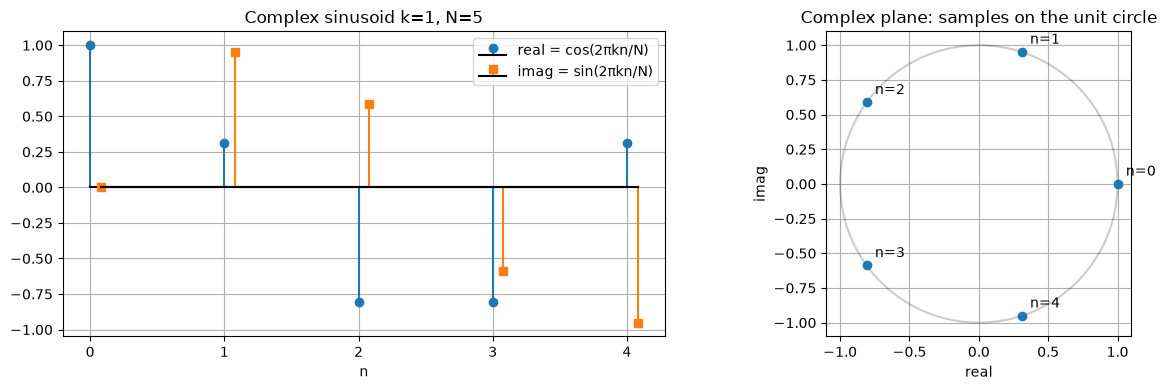

In [33]:
# E2 - 2.2 (corrected / corregido)

k, N = 1, 5
c_sine = gen_complex_sine(k, N)
n = np.arange(N)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].stem(n, c_sine.real, linefmt='C0', markerfmt='C0o', basefmt='k', label='real = cos(2πkn/N)')
axes[0].stem(n + 0.08, c_sine.imag, linefmt='C1', markerfmt='C1s', basefmt='k', label='imag = sin(2πkn/N)')
axes[0].set_xlabel('n'); axes[0].set_xticks(n)
axes[0].set_title(f'Complex sinusoid k={k}, N={N}')
axes[0].legend(); axes[0].grid(True)

# complex plane / plano complejo
theta = np.linspace(0, 2*np.pi, 300)
axes[1].plot(np.cos(theta), np.sin(theta), 'k', alpha=0.2)
axes[1].plot(c_sine.real, c_sine.imag, 'o')
for i, z in enumerate(c_sine):
    axes[1].annotate(f'n={i}', (z.real, z.imag), textcoords='offset points', xytext=(6, 6))
axes[1].set_aspect('equal'); axes[1].grid(True)
axes[1].set_xlabel('real'); axes[1].set_ylabel('imag')
axes[1].set_title('Complex plane: samples on the unit circle')

plt.tight_layout()
plt.show()

### E2 - 2.3 Conceptual questions / Preguntas conceptuales

**Question 1 – Phase increment / Incremento de fase**

**🇬🇧** Your method is right: compare two consecutive samples in polar form and take the difference of their angles. But the answer needs to give the **actual value** and the relation in a clear way. (Also: the English word is *degrees*, not "grades".)

- Phase of sample $n$: $\angle \bar{x}[n] = 2\pi k n / N$, so the increment from $n$ to $n+1$ is **exactly** $\Delta\phi = 2\pi k/N$, the angular frequency in radians per sample.
- For $k=1, N=5$: $\Delta\phi = 2\pi/5 \approx 1.2566$ rad $= 72°$.
- Equivalently, $\bar{x}[n+1] = \bar{x}[n]\cdot e^{j2\pi k/N}$: each sample is the previous one **rotated** by $2\pi k/N$ on the unit circle. After $N$ samples the sinusoid has turned $k$ full revolutions.
- Careful when computing it numerically: `np.diff(np.angle(x))` can jump by $2\pi$ because `np.angle` wraps to $(-\pi, \pi]$. `np.angle(x[1:] / x[:-1])` avoids this.

**🇪🇸** Tu método es correcto: comparar dos muestras consecutivas en forma polar y restar sus ángulos. Pero la respuesta debe dar el **valor concreto** y la relación de forma clara. (Además, en inglés es *degrees*, no "grades".)

- Fase de la muestra $n$: $\angle \bar{x}[n] = 2\pi k n / N$, así que el incremento de $n$ a $n+1$ es **exactamente** $\Delta\phi = 2\pi k/N$, la frecuencia angular en radianes por muestra.
- Para $k=1, N=5$: $\Delta\phi = 2\pi/5 \approx 1.2566$ rad $= 72°$.
- Equivalentemente, $\bar{x}[n+1] = \bar{x}[n]\cdot e^{j2\pi k/N}$: cada muestra es la anterior **rotada** $2\pi k/N$ en el círculo unidad. Tras $N$ muestras la sinusoide ha dado $k$ vueltas completas.
- Cuidado al calcularlo numéricamente: `np.diff(np.angle(x))` puede saltar $2\pi$ porque `np.angle` está acotado a $(-\pi, \pi]$. `np.angle(x[1:] / x[:-1])` lo evita.

---

**Question 2 – `k=1` vs `k=N-1`**

**🇬🇧** You're on the right track with "opposite sign", but you said the phase is *the same*, and it's the opposite. To be precise:

- **Real parts are identical**, and **imaginary parts have opposite sign**. So `k=N-1` is the **complex conjugate** of `k=1`: $\bar{x}_{N-1}[n] = \bar{x}_1^*[n]$.
- **Why:** $e^{j2\pi (N-1)n/N} = e^{j2\pi n}\cdot e^{-j2\pi n/N} = e^{-j2\pi n/N}$, because $e^{j2\pi n} = 1$ for every integer $n$. Then $\cos$ is even (the real part stays the same) and $\sin$ is odd (the imaginary part changes sign).
- **Interpretation:** bin $k=N-1$ is really frequency $-1$, a **negative frequency**. Its phase increment is $2\pi(N-1)/N = 288°$, which is the same as $-72°$, so it turns around the circle **clockwise** at the same speed. This is the aliasing from Part 1 again: once sampled, frequencies $k$ and $k-N$ are indistinguishable. That's why, for a real signal, the upper half of the DFT mirrors the lower half.

**🇪🇸** Vas bien con lo del "signo opuesto", pero dijiste que la fase es *la misma*, y es la opuesta. Para precisar:

- **Las partes reales son idénticas** y **las imaginarias tienen signo opuesto**. Es decir, `k=N-1` es el **conjugado complejo** de `k=1`: $\bar{x}_{N-1}[n] = \bar{x}_1^*[n]$.
- **Por qué:** $e^{j2\pi (N-1)n/N} = e^{j2\pi n}\cdot e^{-j2\pi n/N} = e^{-j2\pi n/N}$, porque $e^{j2\pi n} = 1$ para todo entero $n$. Además, $\cos$ es par (la parte real no cambia) y $\sin$ es impar (la parte imaginaria cambia de signo).
- **Interpretación:** el bin $k=N-1$ es en realidad la frecuencia $-1$, una **frecuencia negativa**. Su incremento de fase es $2\pi(N-1)/N = 288°$, que equivale a $-72°$, así que gira por el círculo en sentido **horario** a la misma velocidad. Es otra vez el aliasing de la Parte 1: una vez muestreadas, las frecuencias $k$ y $k-N$ no se distinguen. Por eso, para una señal real, la mitad superior de la DFT es un espejo de la mitad inferior.

Q1 phase increments k=1  (rad): [1.25663706 1.25663706 1.25663706 1.25663706]  -> 2*pi*k/N = 1.2566370614359172
                         (deg): [72. 72. 72. 72.]
   phase increments k=N-1 (deg): [-72. -72. -72. -72.] (= 288° wrapped to -72°)

Q2 real parts equal:       True
   imag parts opposite:     True
   cN1 == conj(c1):         True


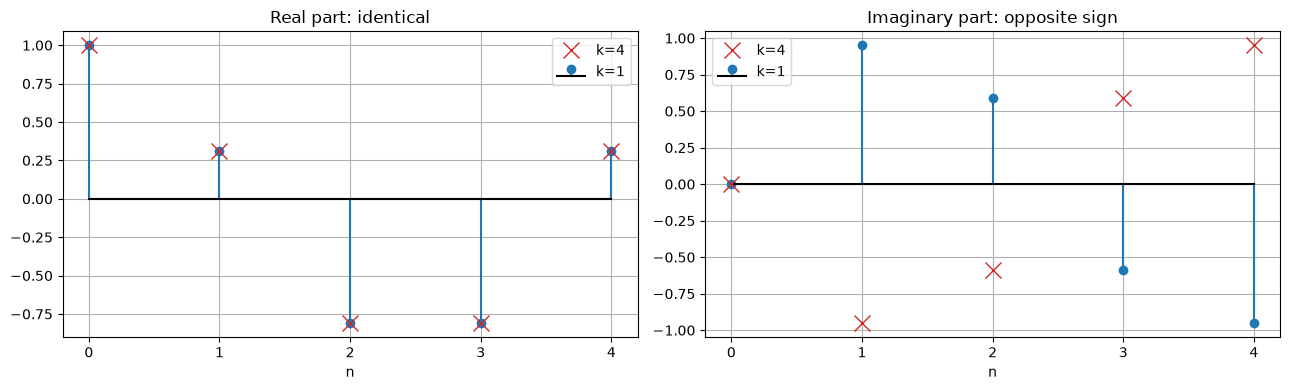

In [34]:
# E2 - 2.3 check / comprobación

N = 5
c1 = gen_complex_sine(1, N)
cN1 = gen_complex_sine(N - 1, N)

# Q1: phase increment / incremento de fase
dphi = np.angle(c1[1:] / c1[:-1])
print('Q1 phase increments k=1  (rad):', dphi, ' -> 2*pi*k/N =', 2*np.pi*1/N)
print('                         (deg):', np.degrees(dphi))
print('   phase increments k=N-1 (deg):', np.degrees(np.angle(cN1[1:] / cN1[:-1])), '(= 288° wrapped to -72°)')

# Q2: conjugate relationship / relación de conjugado
print('\nQ2 real parts equal:      ', np.allclose(c1.real, cN1.real))
print('   imag parts opposite:    ', np.allclose(c1.imag, -cN1.imag))
print('   cN1 == conj(c1):        ', np.allclose(cN1, np.conj(c1)))

n = np.arange(N)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].stem(n, c1.real, linefmt='C0', markerfmt='C0o', basefmt='k', label='k=1')
axes[0].plot(n, cN1.real, 'C3x', markersize=12, label=f'k={N-1}')
axes[0].set_title('Real part: identical'); axes[0].legend(); axes[0].grid(True)
axes[1].stem(n, c1.imag, linefmt='C0', markerfmt='C0o', basefmt='k', label='k=1')
axes[1].plot(n, cN1.imag, 'C3x', markersize=12, label=f'k={N-1}')
axes[1].set_title('Imaginary part: opposite sign'); axes[1].legend(); axes[1].grid(True)
for ax in axes: ax.set_xlabel('n'); ax.set_xticks(n)
plt.tight_layout()
plt.show()

---

## Part 3 – Implement the discrete Fourier transform (DFT)

The function `dft()` should implement the DFT equation above.

Given a sequence `x` of length `N`, return its spectrum `X` of length `N`, with frequency-bin indices from `0` to `N-1`.

In [43]:
# E2 - 3.1: Complete function dft()

def dft(x):
    """Compute the N-point DFT of a sequence.

    Args:
        x (np.array): input sequence of length N

    Returns:
        np.array: DFT spectrum of x (length N)
    """
    ### Your code here
    N = len(x)
    x_dft = []
    for k in range(N):
        x_k = 0 
        for n in range(N):                 # sample indices 0..N-1 / índices de muestra
            x_k_n = x[n]*np.exp(1j*2*np.pi*k*n/N)
            x_k += x_k_n        
        x_dft.append(x_k)
    return x_dft





If you run `dft()` with `x = np.array([1, 2, 3, 4])`, it should return:

```
array([10.0 + 0.0j, -2.0 + 2.0j, -2.0 - 9.79717439e-16j, -2.0 - 2.0j])
```

You may not obtain exact zeros due to floating-point precision. Values around `1e-15` are numerical error and can be treated as zero.

In [44]:
# E2 - 3.2: Call dft() with x = [1, 2, 3, 4],
#            then plot real and imaginary parts of the output spectrum.


print(dft([1,2,3,4]))
### Your code here

[np.complex128(10+0j), np.complex128(-2.0000000000000004-1.9999999999999996j), np.complex128(-2+9.797174393178826e-16j), np.complex128(-1.9999999999999982+2.000000000000001j)]


**E2 - 3.3: Conceptual questions (answer here)**

1. In your own words, what does each DFT bin `X[k]` measure about the input signal?
2. For `x=[1,2,3,4]`, identify which bin corresponds to the DC component and verify it numerically from your output.
3. Compare your `dft(x)` output with `np.fft.fft(x)` for one test case of your choice. Are they the same (up to numerical precision)? If not, explain where they differ.

In [45]:
# 1. The contribution of each wave of simple frequency k to compound the resulting wave. The magnitude of the wave (real part) represent the amount of this single wave compouds the final one and the phase the phase of this wave basically. 


In [ ]:
# 2. np.mean(x) is the DC. The ideal case with DC_offset 0 schould be the mean 

In [ ]:
3. # do it by yourself AI, I guess according which float is usinmg each one 

---
## Part 3 – Corrections / Correcciones

### E2 - 3.1 `dft()`

**🇬🇧 English**

1. ❌ **Wrong sign in the exponent (main error).** You wrote `np.exp(1j*...)`, but the DFT uses $e^{-j2\pi kn/N}$, with a **minus** sign. With `+` you are computing the conjugate spectrum $X^*[k]$, not $X[k]$. That's why your output has `X[1] = -2-2j` and `X[3] = -2+2j`: they're swapped compared to the expected `-2+2j` and `-2-2j`.
   - Winding view: the DFT winds the signal **clockwise** (the minus sign). With `+` you wind counter-clockwise, so bin $k$ measures frequency $-k$, which is bin $N-k$.
   - That's also why Part 2 says "*In DFT computation we use the conjugate complex exponential*": $X[k] = \sum_n x[n]\,\overline{\bar{x}_k[n]}$, the sum of $x$ times the **conjugate** of `gen_complex_sine(k, N)`.
2. **It returns a Python list**, while the instructions ask for an `np.array`. That's why the output shows `np.complex128(...)` items one by one. Use `return np.array(x_dft)`.
3. **Optional:** the inner loop can be one line with NumPy: `np.sum(x * np.exp(-1j*2*np.pi*k*n/N))`.

**🇪🇸 Español**

1. ❌ **Signo incorrecto en el exponente (error principal).** Escribiste `np.exp(1j*...)`, pero la DFT usa $e^{-j2\pi kn/N}$, con signo **menos**. Con `+` calculas el espectro conjugado $X^*[k]$, no $X[k]$. Por eso tu salida da `X[1] = -2-2j` y `X[3] = -2+2j`: están intercambiados respecto a los esperados `-2+2j` y `-2-2j`.
   - Visto como enrollado: la DFT enrolla la señal en sentido **horario** (el signo menos). Con `+` enrollas en sentido antihorario, así que el bin $k$ mide la frecuencia $-k$, que es el bin $N-k$.
   - Por eso la Parte 2 dice "*In DFT computation we use the conjugate complex exponential*": $X[k] = \sum_n x[n]\,\overline{\bar{x}_k[n]}$, la suma de $x$ por el **conjugado** de `gen_complex_sine(k, N)`.
2. **Devuelve una lista de Python**, y el enunciado pide un `np.array`. Por eso la salida muestra los elementos `np.complex128(...)` uno a uno. Usa `return np.array(x_dft)`.
3. **Opcional:** el bucle interno puede ser una sola línea con NumPy: `np.sum(x * np.exp(-1j*2*np.pi*k*n/N))`.

In [47]:
# E2 - 3.1 (corrected / corregido)

def dft(x):
    """Compute the N-point DFT of a sequence."""
    x = np.asarray(x)
    N = len(x)
    n = np.arange(N)
    X = np.zeros(N, dtype=complex)
    for k in range(N):
        X[k] = np.sum(x * np.exp(-1j * 2 * np.pi * k * n / N))   # minus sign! / ¡signo menos!
        # equivalent / equivalente: np.sum(x * np.conj(gen_complex_sine(k, N)))
    return X

print(dft(np.array([1, 2, 3, 4])))
# expected / esperado: [10.+0.j  -2.+2.j  -2.-9.79717439e-16j  -2.-2.j]

[10.+0.00000000e+00j -2.+2.00000000e+00j -2.-9.79717439e-16j
 -2.-2.00000000e+00j]


### E2 - 3.2 Plot / Gráfica

**🇬🇧** The plot is missing again: you only printed the output. Below are the real and imaginary parts, plus the magnitude and phase, which are the usual way to read a spectrum.

**🇪🇸** Falta otra vez la gráfica: solo imprimiste la salida. Abajo están la parte real y la imaginaria, y además el módulo y la fase, que es la forma habitual de leer un espectro.

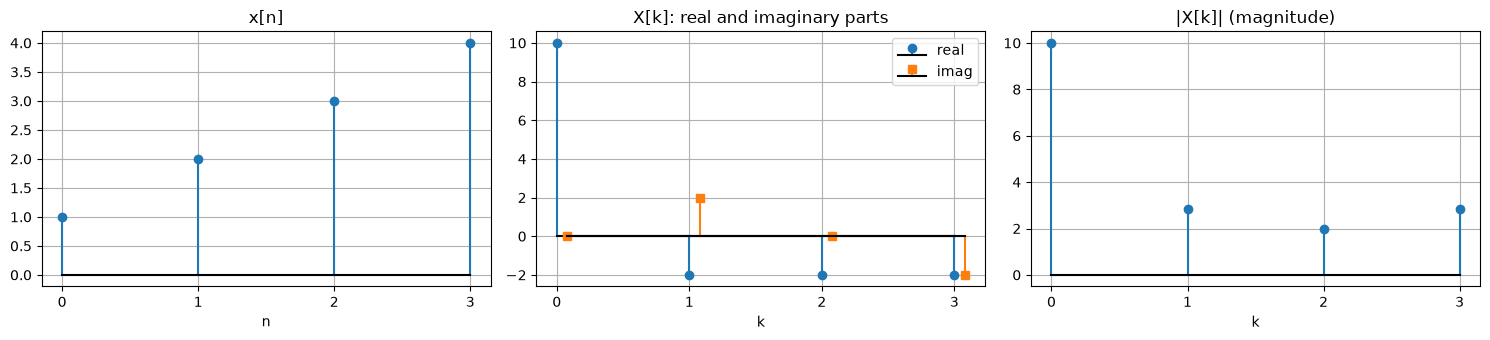

In [48]:
# E2 - 3.2 (corrected / corregido)

x = np.array([1, 2, 3, 4])
X = dft(x)
k = np.arange(len(X))

fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
axes[0].stem(k, x, basefmt='k')
axes[0].set_title('x[n]'); axes[0].set_xlabel('n')
axes[1].stem(k, X.real, linefmt='C0', markerfmt='C0o', basefmt='k', label='real')
axes[1].stem(k + 0.08, X.imag, linefmt='C1', markerfmt='C1s', basefmt='k', label='imag')
axes[1].set_title('X[k]: real and imaginary parts'); axes[1].set_xlabel('k'); axes[1].legend()
axes[2].stem(k, np.abs(X), basefmt='k')
axes[2].set_title('|X[k]| (magnitude)'); axes[2].set_xlabel('k')
for ax in axes: ax.set_xticks(k); ax.grid(True)
plt.tight_layout()
plt.show()

### E2 - 3.3 Conceptual questions / Preguntas conceptuales

**Question 1 – What does `X[k]` measure? / ¿Qué mide `X[k]`?**

**🇬🇧** The idea is right: how much of the frequency-$k$ wave is in the signal, and with what phase. But there is one mistake: **the magnitude is not the real part.** $X[k]$ is a complex number, and:
- **magnitude** $|X[k]| = \sqrt{\mathrm{Re}^2 + \mathrm{Im}^2}$ is *how much* of that frequency there is;
- **phase** $\angle X[k]$ = `np.angle(X[k])` is *where that component starts*, its initial phase $\varphi$.

The real part alone mixes the two. For example, a pure sine has a DFT that is purely imaginary, so its real part is 0 even though the sine is there.

A more precise answer: $X[k]$ is the **correlation (dot product)** of $x$ with the complex sinusoid of $k$ turns in $N$ samples. In the winding picture, it is **$N$ times the center of mass** of the samples wound at $k$ turns per $N$ samples. If $x$ has a component at that frequency, the points pile up on one side and $|X[k]|$ is large. If not, they spread evenly around the circle and $X[k] \approx 0$.
- Bin $k$ corresponds to the frequency $f_k = k\,f_s/N$ Hz. For $k > N/2$, it's the negative frequency $(k-N)f_s/N$ (see Part 2).
- Scale: a real cosine $A\cos(2\pi k_0 n/N + \varphi)$ gives $|X[k_0]| = |X[N-k_0]| = A N/2$ and $\angle X[k_0] = \varphi$.

**🇪🇸** La idea es correcta: cuánto hay de la onda de frecuencia $k$ en la señal y con qué fase. Pero hay un error: **el módulo no es la parte real.** $X[k]$ es un número complejo, y:
- el **módulo** $|X[k]| = \sqrt{\mathrm{Re}^2 + \mathrm{Im}^2}$ es *cuánto* hay de esa frecuencia;
- la **fase** $\angle X[k]$ = `np.angle(X[k])` es *dónde empieza esa componente*, su fase inicial $\varphi$.

La parte real sola mezcla las dos cosas. Por ejemplo, un seno puro tiene una DFT puramente imaginaria, así que su parte real es 0 aunque el seno esté ahí.

Una respuesta más precisa: $X[k]$ es la **correlación (producto escalar)** de $x$ con la sinusoide compleja de $k$ vueltas en $N$ muestras. En la imagen del enrollado, es **$N$ veces el centro de masa** de las muestras enrolladas a $k$ vueltas por cada $N$ muestras. Si $x$ tiene una componente a esa frecuencia, los puntos se acumulan en un lado y $|X[k]|$ es grande. Si no, se reparten por igual alrededor del círculo y $X[k] \approx 0$.
- El bin $k$ corresponde a la frecuencia $f_k = k\,f_s/N$ Hz. Si $k > N/2$, es la frecuencia negativa $(k-N)f_s/N$ (ver la Parte 2).
- Escala: un coseno real $A\cos(2\pi k_0 n/N + \varphi)$ da $|X[k_0]| = |X[N-k_0]| = A N/2$ y $\angle X[k_0] = \varphi$.

---

**Question 2 – DC component / Componente DC**

**🇬🇧** You didn't say **which bin** it is, which is what the question asks, and you didn't verify it from your output.
- DC is **bin $k=0$**: with $k=0$ the exponential is $e^0 = 1$, so there's no winding at all and $X[0] = \sum_n x[n]$.
- For `x=[1,2,3,4]`: $X[0] = 1+2+3+4 = 10$ ✅, which matches your output `10+0j`. Its imaginary part is always 0 for a real signal.
- The **mean** (the DC offset) is $X[0]/N = 10/4 = 2.5$ = `np.mean(x)`. So `np.mean(x)` is the DC *value*, but the DFT bin itself is $N$ times bigger. In the winding picture, $X[0]/N$ is the center of mass when you don't wind at all.

**🇪🇸** No dijiste **qué bin** es, que es lo que pide la pregunta, ni lo comprobaste con tu salida.
- La DC es el **bin $k=0$**: con $k=0$ la exponencial vale $e^0 = 1$, así que no hay enrollado y $X[0] = \sum_n x[n]$.
- Para `x=[1,2,3,4]`: $X[0] = 1+2+3+4 = 10$ ✅, que coincide con tu salida `10+0j`. Su parte imaginaria siempre es 0 para una señal real.
- La **media** (el desplazamiento DC) es $X[0]/N = 10/4 = 2.5$ = `np.mean(x)`. Así que `np.mean(x)` es el *valor* de la DC, pero el bin de la DFT es $N$ veces mayor. En la imagen del enrollado, $X[0]/N$ es el centro de masa cuando no enrollas nada.

---

**Question 3 – `dft(x)` vs `np.fft.fft(x)`**

**🇬🇧** (This one was left for you to do. Run the cell below.)
- **With your original `dft()` they do NOT match.** Your output is the **complex conjugate** of `np.fft.fft(x)`, because of the `+` sign. The real parts are equal and the imaginary parts have opposite sign; bins 1 and 3 are swapped.
- **With the corrected `dft()` they match**, with a maximum error of about $10^{-15}$.
- The tiny difference is **not** because they use different float types: both use `float64`/`complex128`. It's because they **compute in a different order**. `np.fft.fft` uses the FFT algorithm (Cooley–Tukey, $O(N\log N)$ operations), while ours is the direct sum ($O(N^2)$). Different sequences of operations give different rounding errors. The error grows a little with $N$ (about $10^{-13}$ for $N=64$), but it's always negligible. The FFT is the same transform, only much faster.

**🇪🇸** (Esta la dejaste para hacer. Ejecuta la celda de abajo.)
- **Con tu `dft()` original NO coinciden.** Tu salida es el **conjugado complejo** de `np.fft.fft(x)`, por el signo `+`. Las partes reales son iguales y las imaginarias tienen signo opuesto; los bins 1 y 3 están intercambiados.
- **Con la `dft()` corregida coinciden**, con un error máximo de unos $10^{-15}$.
- La pequeña diferencia **no** se debe a que usen tipos de float distintos: los dos usan `float64`/`complex128`. Se debe a que **calculan en otro orden**. `np.fft.fft` usa el algoritmo FFT (Cooley–Tukey, $O(N\log N)$ operaciones), y el nuestro es la suma directa ($O(N^2)$). Secuencias de operaciones distintas dan errores de redondeo distintos. El error crece un poco con $N$ (unos $10^{-13}$ para $N=64$), pero siempre es despreciable. La FFT es la misma transformada, solo que mucho más rápida.

Note / Nota: your cell `3. # do it by yourself AI...` runs without error only by accident: `3.` is the float `3.0` / `3.` es el float `3.0`.

In [49]:
# E2 - 3.3 check / comprobación

x = np.array([1, 2, 3, 4])
X_fft = np.fft.fft(x)

# your original version (with + sign) / tu versión original (con signo +)
N = len(x); n = np.arange(N)
X_plus = np.array([np.sum(x * np.exp(+1j*2*np.pi*k*n/N)) for k in range(N)])

print('np.fft.fft(x):        ', np.round(X_fft, 10))
print('dft with + sign:      ', np.round(X_plus, 10))
print('  equals conj(fft)?   ', np.allclose(X_plus, np.conj(X_fft)))
print('dft corrected:        ', np.round(dft(x), 10))
print('  max |dft - fft|:    ', np.max(np.abs(dft(x) - X_fft)))

# Q2: DC
print('\nQ2  X[0] =', dft(x)[0], '= sum(x) =', np.sum(x), ';  X[0]/N =', dft(x)[0].real / N, '= mean(x) =', np.mean(x))

# Q3 with a longer random signal / con una señal aleatoria más larga
r = np.random.default_rng(0).standard_normal(64)
print('\nQ3  N=64 random signal, max |dft - fft|:', np.max(np.abs(dft(r) - np.fft.fft(r))))

# Q1: a cosine A*cos(2*pi*k0*n/N + phi) -> |X[k0]| = A*N/2, angle = phi
A, k0, phi, N = 0.8, 3, 0.5, 16
xc = A * np.cos(2*np.pi*k0*np.arange(N)/N + phi)
Xc = dft(xc)
print(f'\nQ1  cosine A={A}, k0={k0}, phi={phi}, N={N}:  |X[k0]| = {abs(Xc[k0]):.4f} (A*N/2 = {A*N/2}),  angle(X[k0]) = {np.angle(Xc[k0]):.4f}')
print(f'    |X[N-k0]| = {abs(Xc[N-k0]):.4f},  angle(X[N-k0]) = {np.angle(Xc[N-k0]):.4f}  (negative frequency, phase -phi)')

np.fft.fft(x):         [10.+0.j -2.+2.j -2.+0.j -2.-2.j]
dft with + sign:       [10.+0.j -2.-2.j -2.+0.j -2.+2.j]
  equals conj(fft)?    True
dft corrected:         [10.+0.j -2.+2.j -2.-0.j -2.-2.j]
  max |dft - fft|:     1.9860273225978185e-15

Q2  X[0] = (10+0j) = sum(x) = 10 ;  X[0]/N = 2.5 = mean(x) = 2.5

Q3  N=64 random signal, max |dft - fft|: 2.514925462074474e-13

Q1  cosine A=0.8, k0=3, phi=0.5, N=16:  |X[k0]| = 6.4000 (A*N/2 = 6.4),  angle(X[k0]) = 0.5000
    |X[N-k0]| = 6.4000,  angle(X[N-k0]) = -0.5000  (negative frequency, phase -phi)


---

## Part 4 – Implement the inverse discrete Fourier transform (IDFT)

The function `idft()` should implement the IDFT equation above.

Given a frequency spectrum `X` of length `N`, return its time-domain sequence `x` (also length `N`). Assume frequency-bin indices range from `0` to `N-1`.

Remember to apply the `1/N` scaling factor.

In [54]:
# E2 - 4.1: Complete function idft()




def idft(x):
    """Compute the N-point IDFT of a spectrum.

    Args:
        X (np.array): input spectrum of length N

    Returns:
        np.array: IDFT of X (length N)
    """
    ### Your code here
    N = len(x)
    x_idft = []
    for n in range(N):
        x_n = 0 
        for k in range(N):                 # sample indices 0..N-1 / índices de muestra
            x_n_k = x[k]*np.exp(1j*2*np.pi*k*n/N)
            x_n += x_n_k        
        x_idft.append(x_n/N)
    return x_idft

    

If you run `idft()` with `X = np.array([1, 1, 1, 1])`, the output should be close to:

```
array([ 1.00000000e+00+0.00000000e+00j, -4.59242550e-17+5.55111512e-17j,
        0.00000000e+00+6.12323400e-17j,  8.22616137e-17+8.32667268e-17j])
```

This is essentially `[1, 0, 0, 0]`, with tiny floating-point residuals. As a validation, you can compute `dft(idft(X))` and check that it returns the original `X` (up to numerical error).

In [56]:
# E2 - 4.2: Plot real/imaginary parts of X = [1, 1, 1, 1], call idft(),
#            plot real/imaginary parts of the output sequence,
#            then compute dft() of that output to validate reconstruction.

### Your code here




dft(idft([1,1,1,1]))

array([1.+2.00010218e-16j, 1.+6.69535287e-17j, 1.-7.75455381e-17j,
       1.-1.89418209e-16j])

**E2 - 4.3: Conceptual questions (answer here)**

1. Why does the IDFT include the factor `1/N` while the DFT (as implemented here) does not?
2. Use one example where you compute `x_hat = idft(dft(x))`. How close is `x_hat` to `x`? Report the maximum absolute error.
3. Your IDFT output may contain tiny imaginary residuals for real signals. Why do these appear, and when is it safe to discard them with `np.real(...)`?

In [57]:
# No idea 
# do it 
# discard them when the absolute error of the last section must be of the same order, approx of this residual

---
## Part 4 – Corrections / Correcciones

### E2 - 4.1 `idft()`

**🇬🇧** ✅ **The math is correct.** The sign is `+` (correct for the inverse, where you "unwind" in the opposite direction to the DFT) and you divide by `N`. Two small issues:
1. **It returns a Python list** instead of an `np.array`, as in Part 3. Use `return np.array(x_idft)`.
2. **The parameter is named `x`**, but it is a spectrum. The docstring and the exercise call it `X`. Lowercase `x` usually means time and uppercase `X` frequency, so `idft(x)` is misleading.

**🇪🇸** ✅ **Las matemáticas están bien.** El signo es `+` (correcto en la inversa, donde "desenrollas" en sentido contrario a la DFT) y divides por `N`. Dos detalles:
1. **Devuelve una lista de Python** en lugar de un `np.array`, igual que en la Parte 3. Usa `return np.array(x_idft)`.
2. **El parámetro se llama `x`**, pero es un espectro. El docstring y el enunciado lo llaman `X`. La minúscula `x` suele indicar tiempo y la mayúscula `X` frecuencia, así que `idft(x)` confunde.

In [58]:
# E2 - 4.1 (corrected / corregido)

def idft(X):
    """Compute the N-point IDFT of a spectrum."""
    X = np.asarray(X)
    N = len(X)
    k = np.arange(N)
    x = np.zeros(N, dtype=complex)
    for n in range(N):
        x[n] = np.sum(X * np.exp(1j * 2 * np.pi * k * n / N)) / N   # plus sign and 1/N / signo más y 1/N
    return x

print(idft(np.array([1, 1, 1, 1])))
# expected / esperado: ~[1, 0, 0, 0]

[ 1.00000000e+00+0.00000000e+00j -5.55111512e-17+2.77555756e-17j
  0.00000000e+00+6.12323400e-17j  8.32667268e-17+1.11022302e-16j]


### E2 - 4.2 Plots and validation / Gráficas y validación

**🇬🇧** You did the validation `dft(idft(X))` ✅, and it correctly gives `[1, 1, 1, 1]` with residuals around $10^{-16}$. But the three plots the exercise asks for are missing (`X`, `idft(X)` and `dft(idft(X))`), and you never printed `idft(X)` itself, which is the result you're asked to check against the expected `[1, 0, 0, 0]`.

**🇪🇸** Hiciste la validación `dft(idft(X))` ✅, y da correctamente `[1, 1, 1, 1]` con residuos de unos $10^{-16}$. Pero faltan las tres gráficas que pide el ejercicio (`X`, `idft(X)` y `dft(idft(X))`), y no imprimiste `idft(X)`, que es el resultado que hay que comparar con el esperado `[1, 0, 0, 0]`.

idft(X)       = [ 1.+0.j -0.+0.j  0.+0.j  0.+0.j]
dft(idft(X))  = [1.+0.j 1.+0.j 1.-0.j 1.-0.j]
max error     = 2.9884426361388694e-16


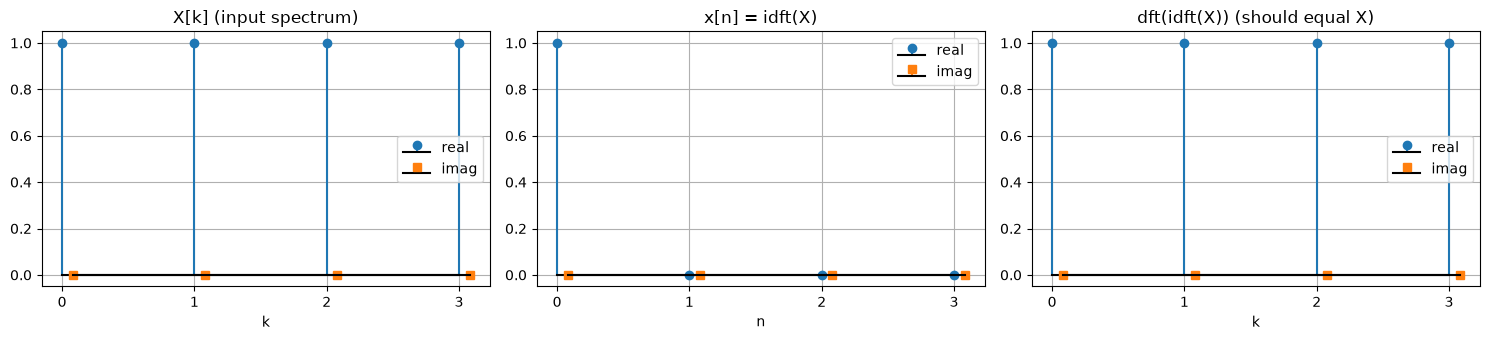

In [59]:
# E2 - 4.2 (corrected / corregido)

X = np.array([1, 1, 1, 1])
x = idft(X)
X_back = dft(x)
k = np.arange(len(X))

print('idft(X)       =', np.round(x, 12))
print('dft(idft(X))  =', np.round(X_back, 12))
print('max error     =', np.max(np.abs(X_back - X)))

fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
for ax, data, title, xlabel in [(axes[0], X, 'X[k] (input spectrum)', 'k'),
                                (axes[1], x, 'x[n] = idft(X)', 'n'),
                                (axes[2], X_back, 'dft(idft(X)) (should equal X)', 'k')]:
    ax.stem(k, np.real(data), linefmt='C0', markerfmt='C0o', basefmt='k', label='real')
    ax.stem(k + 0.08, np.imag(data), linefmt='C1', markerfmt='C1s', basefmt='k', label='imag')
    ax.set_title(title); ax.set_xlabel(xlabel); ax.set_xticks(k); ax.grid(True); ax.legend()
plt.tight_layout()
plt.show()

### E2 - 4.3 Conceptual questions / Preguntas conceptuales

**Question 1 – Why `1/N`? / ¿Por qué `1/N`?**

**🇬🇧** Because the complex sinusoids of the DFT are **orthogonal but not normalized**: each one has "energy" $N$, not 1.

$$\sum_{n=0}^{N-1} e^{j2\pi kn/N}\,e^{-j2\pi mn/N} = \sum_{n=0}^{N-1} e^{j2\pi (k-m)n/N} = \begin{cases} N & k = m \\ 0 & k \neq m \end{cases}$$

When you do DFT and then IDFT without any factor, each component is multiplied by $N$: `idft_without_1/N(dft(x)) = N·x`. The $1/N$ cancels that factor.
- Winding view: $X[k]$ is **$N$ times** the center of mass, so the inverse must divide by $N$ to recover the original amplitudes.
- Example: $X = [1,1,1,1]$. Without $1/N$ you'd get $x[0] = 1+1+1+1 = 4$ instead of $1$.
- **Where** you put the factor is a convention. It could go in the DFT, or you could put $1/\sqrt{N}$ in both (the "unitary" DFT, `np.fft.fft(x, norm='ortho')`). What matters is that the round trip multiplies by exactly $1$. Putting it in the IDFT, as NumPy and sms-tools do, makes $X[0] = \sum x[n]$ and keeps the DFT formula simple.

**🇪🇸** Porque las sinusoides complejas de la DFT son **ortogonales pero no están normalizadas**: cada una tiene "energía" $N$, no 1.

Al hacer DFT y luego IDFT sin ningún factor, cada componente queda multiplicada por $N$: `idft_sin_1/N(dft(x)) = N·x`. El $1/N$ cancela ese factor.
- Visto como enrollado: $X[k]$ es **$N$ veces** el centro de masa, así que la inversa tiene que dividir por $N$ para recuperar las amplitudes originales.
- Ejemplo: $X = [1,1,1,1]$. Sin $1/N$ obtendrías $x[0] = 1+1+1+1 = 4$ en lugar de $1$.
- **Dónde** se pone el factor es una convención. Podría ir en la DFT, o se puede poner $1/\sqrt{N}$ en las dos (la DFT "unitaria", `np.fft.fft(x, norm='ortho')`). Lo importante es que la ida y vuelta multiplique exactamente por $1$. Ponerlo en la IDFT, como hacen NumPy y sms-tools, deja $X[0] = \sum x[n]$ y mantiene simple la fórmula de la DFT.

---

**Question 2 – Reconstruction error / Error de reconstrucción**

**🇬🇧** (Left undone. See the cell below.) With a random signal of $N=64$, `x_hat = idft(dft(x))` matches `x` with a **maximum absolute error of about $10^{-14}$**. That's machine precision (`float64` has about 16 significant digits, and the error grows a little with the $N^2$ operations of the direct sum), so the reconstruction is exact up to rounding. The DFT is invertible and loses no information.

**🇪🇸** (Sin hacer. Ver la celda de abajo.) Con una señal aleatoria de $N=64$, `x_hat = idft(dft(x))` coincide con `x` con un **error absoluto máximo de unos $10^{-14}$**. Eso es la precisión de la máquina (`float64` tiene unas 16 cifras significativas, y el error crece un poco con las $N^2$ operaciones de la suma directa), así que la reconstrucción es exacta salvo redondeo. La DFT es invertible y no pierde información.

---

**Question 3 – Imaginary residuals / Residuos imaginarios**

**🇬🇧** Your idea (compare the size of the residual with the numerical error) points in the right direction, but it's missing **why** they appear and **the real condition**.
- **Why they appear:** `np.exp` cannot be computed exactly. For example, `np.sin(np.pi)` gives `1.22e-16`, not 0. Every product and sum also rounds. In exact arithmetic the imaginary parts would cancel perfectly, but with floats a remainder of about $10^{-16}$ times the size of the values is left over.
- **When it is safe to discard them:** when the spectrum has **Hermitian symmetry**, $X[N-k] = X^*[k]$ (the real part is symmetric and the imaginary part antisymmetric). That's the condition for $x$ to be real in exact arithmetic. It's always true for `dft(x)` of a real `x`. In that case, `np.real(...)` only removes rounding noise.
- **Practical check:** before discarding, verify that `np.max(np.abs(x.imag))` is tiny compared with `np.max(np.abs(x.real))`, for example below $10^{-10}$ times it.
- **When it is NOT safe:** if the imaginary part is large, the signal is genuinely complex, or there's a bug. Examples: you edited only one half of the spectrum (e.g. a filter applied only to positive frequencies), or you got a sign wrong. `X = [0, 1, 0, 0]` is not Hermitian, and `idft` gives the complex sinusoid $\frac{1}{4}e^{j2\pi n/4}$. Taking `np.real` would hide the error and give a different signal.

**🇪🇸** Tu idea (comparar el tamaño del residuo con el error numérico) va en buena dirección, pero falta **por qué** aparecen y **la condición de verdad**.
- **Por qué aparecen:** `np.exp` no se puede calcular exactamente. Por ejemplo, `np.sin(np.pi)` da `1.22e-16`, no 0. Cada producto y cada suma también redondean. En aritmética exacta las partes imaginarias se cancelarían del todo, pero con floats queda un resto de unos $10^{-16}$ por el tamaño de los valores.
- **Cuándo es seguro descartarlos:** cuando el espectro tiene **simetría hermítica**, $X[N-k] = X^*[k]$ (parte real simétrica y parte imaginaria antisimétrica). Esa es la condición para que $x$ sea real en aritmética exacta. Siempre se cumple para `dft(x)` de una `x` real. En ese caso, `np.real(...)` solo elimina ruido de redondeo.
- **Comprobación práctica:** antes de descartar, verifica que `np.max(np.abs(x.imag))` es diminuto comparado con `np.max(np.abs(x.real))`, por ejemplo menor que $10^{-10}$ veces.
- **Cuándo NO es seguro:** si la parte imaginaria es grande, la señal es compleja de verdad o hay un bug. Por ejemplo: modificaste solo una mitad del espectro (como un filtro aplicado solo a las frecuencias positivas), o te equivocaste de signo. `X = [0, 1, 0, 0]` no es hermítico, e `idft` da la sinusoide compleja $\frac{1}{4}e^{j2\pi n/4}$. Usar `np.real` escondería el error y daría otra señal.

In [60]:
# E2 - 4.3 check / comprobación

# Q1: without 1/N the round trip multiplies by N / sin 1/N la ida y vuelta multiplica por N
X = np.array([1, 1, 1, 1])
print('Q1  idft(X)     =', np.round(idft(X).real, 10))
print('    N * idft(X) =', np.round(len(X) * idft(X).real, 10), ' <- what you would get without 1/N')

# Q2: reconstruction error / error de reconstrucción
x = np.random.default_rng(0).standard_normal(64)
x_hat = idft(dft(x))
print('\nQ2  max |x_hat - x| =', np.max(np.abs(x_hat - x)))

# Q3: residuals / residuos
print('\nQ3  np.sin(np.pi) =', np.sin(np.pi))
print('    max |imag(x_hat)| =', np.max(np.abs(x_hat.imag)), ' vs max |real| =', np.max(np.abs(x_hat.real)))
Xs = dft(x)
N = len(Xs)
print('    Hermitian symmetry X[N-k] == conj(X[k]):', np.allclose(Xs[(-np.arange(N)) % N], np.conj(Xs)))

X_bad = np.array([0, 1, 0, 0])   # not Hermitian / no hermítico
print('    idft([0,1,0,0]) =', np.round(idft(X_bad), 3), ' <- genuinely complex, do NOT discard imag')

Q1  idft(X)     = [ 1. -0.  0.  0.]
    N * idft(X) = [ 4. -0.  0.  0.]  <- what you would get without 1/N

Q2  max |x_hat - x| = 1.97620136936479e-14

Q3  np.sin(np.pi) = 1.2246467991473532e-16
    max |imag(x_hat)| = 1.5085155347094314e-14  vs max |real| = 2.3250307746388272
    Hermitian symmetry X[N-k] == conj(X[k]): True
    idft([0,1,0,0]) = [ 0.25+0.j    0.  +0.25j -0.25+0.j   -0.  -0.25j]  <- genuinely complex, do NOT discard imag


---

## Part 5 – Compute the magnitude spectrum

The function `gen_mag_spec()` should compute the magnitude spectrum of an input sequence `x` of length `N`.

Return an `N`-point magnitude spectrum with frequency-bin indices from `0` to `N-1`.

In [62]:
# E2 - 5.1: Complete function gen_mag_spec()

def gen_mag_spec(x):
    """Compute magnitude spectrum of a sequence.

    Args:
        x (np.array): input sequence of length N

    Returns:
        np.array: magnitude spectrum of x (length N)
    """
    ### Your code here
    return np.abs(dft(x))

print(gen_mag_spec(np.array([1, 2, 3, 4])))
# expected / esperado: [10.  2.82842712  2.  2.82842712]

[10.          2.82842712  2.          2.82842712]


If you run `gen_mag_spec()` with `x = np.array([1, 2, 3, 4])`, it should return:

```
array([10.0, 2.82842712, 2.0, 2.82842712])
```

For a more realistic case, use a longer input such as:

`x = np.cos(2*np.pi*200.0*np.arange(512)/1000)`

Then plot both input and output using `plt.plot(x)` and `plt.plot(X)`.

peak bin = 102  ->  199.22 Hz   (sinusoid: 200.0 Hz)


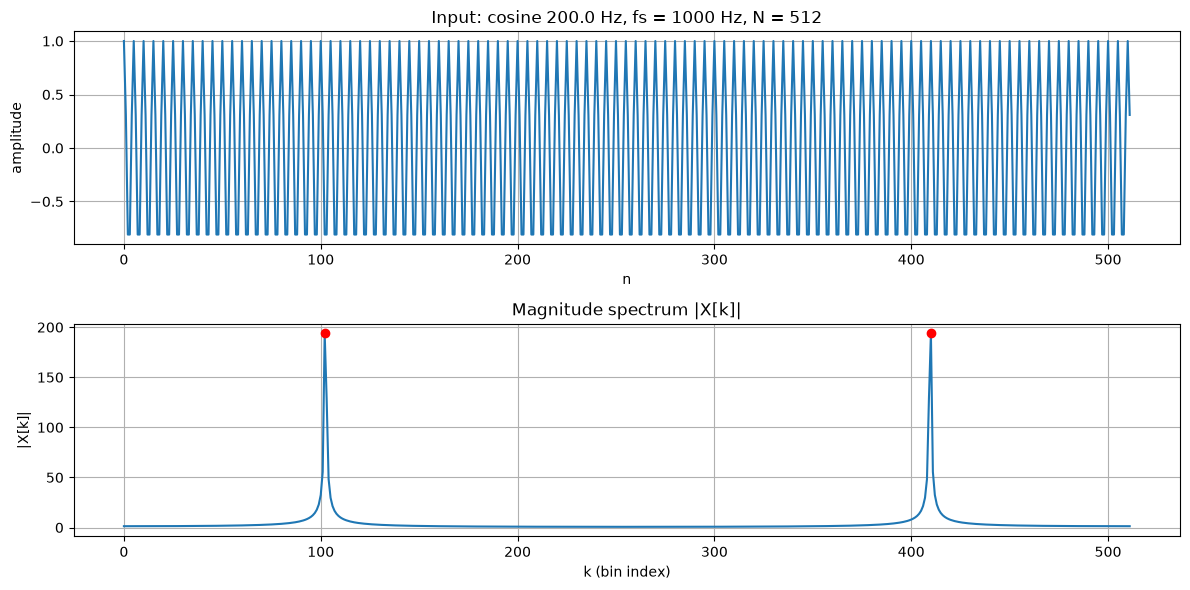

In [63]:
# E2 - 5.2: Plot the input cosine signal, call gen_mag_spec(), and plot the output magnitude spectrum.
#            Validate that the spectral peak matches the sinusoid frequency.

### Your code here
fs, f0, N = 1000, 200.0, 512
x = np.cos(2*np.pi*f0*np.arange(N)/fs)
X = gen_mag_spec(x)

k_peak = np.argmax(X[:N//2])          # peak in the first half (positive frequencies)
print(f'peak bin = {k_peak}  ->  {k_peak*fs/N:.2f} Hz   (sinusoid: {f0} Hz)')

fig, axes = plt.subplots(2, 1, figsize=(12, 6))
axes[0].plot(x)
axes[0].set_title(f'Input: cosine {f0} Hz, fs = {fs} Hz, N = {N}')
axes[0].set_xlabel('n'); axes[0].set_ylabel('amplitude'); axes[0].grid(True)

axes[1].plot(X)
axes[1].plot([k_peak, N-k_peak], X[[k_peak, N-k_peak]], 'ro')
axes[1].set_title('Magnitude spectrum |X[k]|')
axes[1].set_xlabel('k (bin index)'); axes[1].set_ylabel('|X[k]|'); axes[1].grid(True)

plt.tight_layout()
plt.show()

**E2 - 5.3: Conceptual questions (answer here)**

1. From your magnitude spectrum plot, report the bin index of the main peak and convert it to frequency in Hz. Compare with the sinusoid frequency used to generate the signal.
2. Explain why the spectrum of a real cosine shows two symmetric peaks (positive and negative frequency bins in the DFT indexing).
3. Change the sinusoid amplitude from `1.0` to `0.5` (keeping everything else fixed). How does the magnitude spectrum change? Quantify the change in peak magnitude.
4. If the sinusoid frequency is not exactly at a DFT bin center, what effect do you observe in the spectrum? Describe it and explain why it happens.

### E2 - 5.3 Answers / Respuestas

Setup / Configuración: $f_0 = 200$ Hz, $f_s = 1000$ Hz, $N = 512$. Bin spacing (frequency resolution) / separación entre bins (resolución en frecuencia): $\Delta f = f_s/N = 1000/512 \approx 1.953$ Hz.

---

**Question 1 – Peak bin and frequency / Bin del pico y frecuencia**

**🇬🇧**
- The main peak is at **bin $k = 102$**, and its mirror is at $N - 102 = 410$.
- Converted to Hz: $f = k\,f_s/N = 102 \cdot 1000/512 \approx$ **199.22 Hz**.
- The sinusoid is at 200 Hz, so the error is 0.78 Hz, less than half a bin ($\Delta f/2 \approx 0.98$ Hz).
- Why it isn't exact: 200 Hz corresponds to $k = f_0 N/f_s = 102.4$, which falls **between** bins 102 and 103. The DFT only gives values at integer $k$, so the closest bin wins. That's also why bin 103 is high too ($|X[103]| \approx 129$, compared with $|X[102]| \approx 194$): the true frequency is closer to 102 than to 103.

**🇪🇸**
- El pico principal está en el **bin $k = 102$**, y su espejo en $N - 102 = 410$.
- En Hz: $f = k\,f_s/N = 102 \cdot 1000/512 \approx$ **199.22 Hz**.
- La sinusoide es de 200 Hz, así que el error es de 0.78 Hz, menos de medio bin ($\Delta f/2 \approx 0.98$ Hz).
- Por qué no es exacto: 200 Hz corresponde a $k = f_0 N/f_s = 102.4$, que cae **entre** los bins 102 y 103. La DFT solo da valores en $k$ enteros, así que gana el bin más cercano. Por eso el bin 103 también es alto ($|X[103]| \approx 129$, frente a $|X[102]| \approx 194$): la frecuencia real está más cerca de 102 que de 103.

---

**Question 2 – Why two symmetric peaks / Por qué dos picos simétricos**

**🇬🇧**
- A real cosine is the sum of **two complex sinusoids that rotate in opposite directions** (Euler):
$$\cos(2\pi f_0 n/f_s) = \tfrac{1}{2}e^{+j2\pi f_0 n/f_s} + \tfrac{1}{2}e^{-j2\pi f_0 n/f_s}$$
  The DFT detects each one separately: $+f_0$ at bin $k_0 \approx 102$, and $-f_0$ at bin $N - k_0 \approx 410$.
- Why the negative frequency appears at a high bin: as in Part 2, bin $k$ and bin $k - N$ are the same complex sinusoid once sampled (they differ by one extra full turn per $N$ samples). So $-102 \equiv 512 - 102 = 410$.
- Why they are symmetric: for any real $x$, the spectrum has Hermitian symmetry $X[N-k] = X^*[k]$ (Part 4), so $|X[N-k]| = |X[k]|$. The two halves of the magnitude spectrum are mirror images around $N/2 = 256$, which is the Nyquist frequency of 500 Hz. That's why we usually plot only $k = 0 \ldots N/2$.

**🇪🇸**
- Un coseno real es la suma de **dos sinusoides complejas que giran en sentidos opuestos** (Euler). La DFT detecta cada una por separado: $+f_0$ en el bin $k_0 \approx 102$, y $-f_0$ en el bin $N - k_0 \approx 410$.
- Por qué la frecuencia negativa aparece en un bin alto: como en la Parte 2, el bin $k$ y el bin $k - N$ son la misma sinusoide compleja una vez muestreada (se diferencian en una vuelta completa de más cada $N$ muestras). Así que $-102 \equiv 512 - 102 = 410$.
- Por qué son simétricos: para cualquier $x$ real, el espectro tiene simetría hermítica $X[N-k] = X^*[k]$ (Parte 4), así que $|X[N-k]| = |X[k]|$. Las dos mitades del espectro de magnitud son imágenes especulares alrededor de $N/2 = 256$, que es la frecuencia de Nyquist de 500 Hz. Por eso normalmente solo se dibuja $k = 0 \ldots N/2$.

---

**Question 3 – Amplitude 1.0 → 0.5 / Amplitud 1.0 → 0.5**

**🇬🇧**
- The **whole magnitude spectrum is multiplied by 0.5**: same shape, same peak positions, half the height. The peak goes from $|X[102]| \approx 193.9$ to **$\approx 96.95$**, a ratio of exactly 0.5 (−6.02 dB).
- Why: the DFT is **linear**, $\mathrm{DFT}(a\,x) = a\,\mathrm{DFT}(x)$. Every bin scales by the same factor, including the leakage bins (bin 103: 129.0 → 64.5).
- Reference scale: if the frequency fell exactly on a bin, the peak would be $A N/2 = 256$ for $A = 1$ and $128$ for $A = 0.5$. It's lower here (194) because of the leakage in Q4.

**🇪🇸**
- **Todo el espectro de magnitud se multiplica por 0.5**: misma forma, mismas posiciones de los picos, la mitad de altura. El pico pasa de $|X[102]| \approx 193.9$ a **$\approx 96.95$**, una razón exacta de 0.5 (−6.02 dB).
- Por qué: la DFT es **lineal**, $\mathrm{DFT}(a\,x) = a\,\mathrm{DFT}(x)$. Todos los bins se escalan por el mismo factor, incluidos los del leakage (bin 103: 129.0 → 64.5).
- Escala de referencia: si la frecuencia cayera exactamente en un bin, el pico sería $A N/2 = 256$ para $A = 1$ y $128$ para $A = 0.5$. Aquí es menor (194) por el leakage de la P4.

---

**Question 4 – Frequency between bins / Frecuencia entre bins**

**🇬🇧** This is exactly our case: $f_0 = 200$ Hz corresponds to $k = 102.4$.

What you observe is **spectral leakage**:
- Instead of a single line, the energy **spreads to the neighbouring bins**, and in fact to all bins, decaying slowly with distance: 359 of the 512 bins have $|X| > 1$.
- The peak is **lower** than $A N/2$ (194 instead of 256), because the energy is shared among several bins.
- Even the DC bin is no longer 0 ($|X[0]| \approx 1.3$), as discussed after Part 3.

For comparison, with $f_0 = 102 \cdot f_s/N = 199.21875$ Hz (exactly on bin 102), the spectrum has **only 2 nonzero bins** (102 and 410), each of height exactly 256.

Why it happens:
- **Winding view:** the DFT winds the $N$ samples at an integer number of turns $k$. If the signal makes 102.4 periods in the window, there is no integer $k$ at which all its peaks land on the same side of the circle. At $k = 102$ the samples drift by 0.4 of a turn over the window, so the center of mass is smaller than the maximum. At every other $k$ the points don't spread perfectly evenly either, so the center of mass is not exactly 0.
- **Periodicity view:** the DFT treats the $N$ samples as one period of a periodic signal. With 102.4 periods, the end of the window doesn't connect smoothly with the start, so there is a **jump**, and that discontinuity needs many frequencies to be represented.
- **Window view:** cutting $N$ samples is the same as multiplying by a rectangular window. Its spectrum (a periodic sinc) gets centred at $k = 102.4$ and sampled at the integer bins. When the frequency is exactly on a bin, every other bin falls on a zero of the sinc; otherwise they don't.

How to reduce it: use smooth windows (Hann, Hamming, Blackman…), which give much lower sidelobes at the cost of a wider main lobe; or use a larger $N$ or zero-padding to sample the spectrum more finely. This is the topic of the next lecture, the STFT.

**🇪🇸** Es justo nuestro caso: $f_0 = 200$ Hz corresponde a $k = 102.4$.

Lo que se observa es **fuga espectral (leakage)**:
- En lugar de una sola línea, la energía **se reparte en los bins vecinos**, y de hecho en todos, decayendo lentamente con la distancia: 359 de los 512 bins tienen $|X| > 1$.
- El pico es **más bajo** que $A N/2$ (194 en vez de 256), porque la energía se reparte entre varios bins.
- Ni siquiera el bin de DC vale 0 ($|X[0]| \approx 1.3$), como vimos después de la Parte 3.

Para comparar, con $f_0 = 102 \cdot f_s/N = 199.21875$ Hz (exactamente en el bin 102), el espectro tiene **solo 2 bins distintos de cero** (102 y 410), cada uno con altura exactamente 256.

Por qué pasa:
- **Visto como enrollado:** la DFT enrolla las $N$ muestras a un número entero de vueltas $k$. Si la señal hace 102.4 periodos en la ventana, no hay ningún $k$ entero con el que todos sus máximos caigan en el mismo lado del círculo. Con $k = 102$ las muestras se desfasan 0.4 de vuelta a lo largo de la ventana, así que el centro de masa es menor que el máximo. Con cualquier otro $k$ los puntos tampoco se reparten de forma perfectamente uniforme, así que el centro de masa no es exactamente 0.
- **Visto como periodicidad:** la DFT trata las $N$ muestras como un periodo de una señal periódica. Con 102.4 periodos, el final de la ventana no empalma suavemente con el principio, así que hay un **salto**, y esa discontinuidad necesita muchas frecuencias para representarse.
- **Visto como ventana:** cortar $N$ muestras equivale a multiplicar por una ventana rectangular. Su espectro (una sinc periódica) queda centrado en $k = 102.4$ y muestreado en los bins enteros. Cuando la frecuencia cae justo en un bin, todos los demás bins caen en ceros de la sinc; si no, no.

Cómo reducirlo: usar ventanas suaves (Hann, Hamming, Blackman…), que dan lóbulos laterales mucho más bajos a cambio de un lóbulo principal más ancho; o usar un $N$ mayor o zero-padding para muestrear el espectro más finamente. Es el tema de la siguiente clase, la STFT.

Q1  exact bin = 200*N/fs = 102.40;  peak bin = 102 -> 199.22 Hz;  mirror bin = 410
    |X[101]|=55.5  |X[102]|=193.9  |X[103]|=129.0
Q2  |X[k]| == |X[N-k]| for all k: True
Q3  peak A=1: 193.90   A=0.5: 96.95   ratio = 0.500
Q4  off-bin (200 Hz):     peak = 193.9,  bins with |X|>1: 359
    on-bin (199.21875 Hz): peak = 256.0 (= N/2),  bins with |X|>1: 2


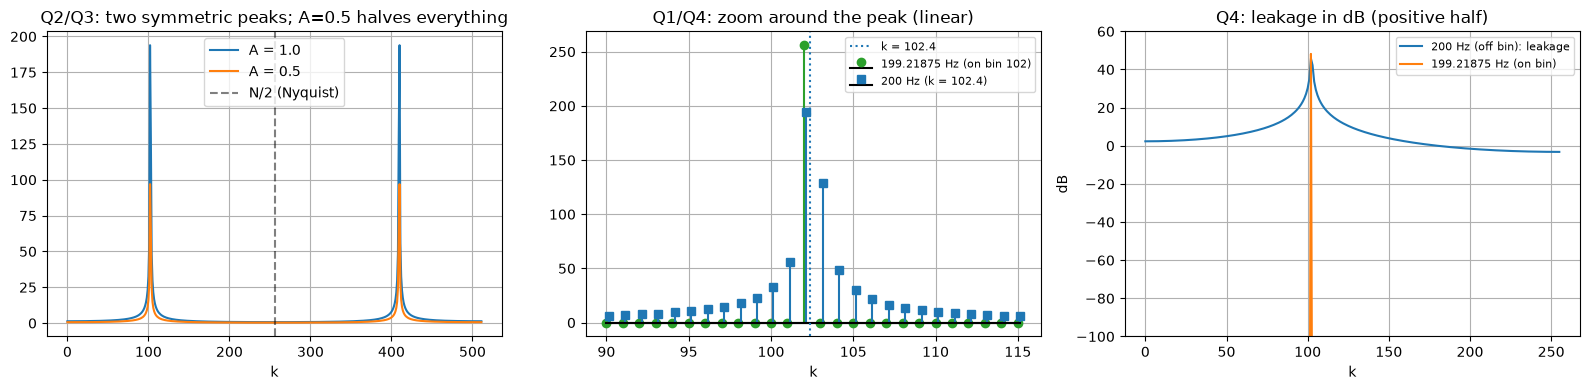

In [64]:
# E2 - 5.3 check / comprobación

fs, N = 1000, 512
n = np.arange(N)
k = np.arange(N)

X1   = gen_mag_spec(1.0 * np.cos(2*np.pi*200.0*n/fs))          # off-bin, A=1   / fuera de bin, A=1
X05  = gen_mag_spec(0.5 * np.cos(2*np.pi*200.0*n/fs))          # off-bin, A=0.5 / fuera de bin, A=0.5
f_on = 102 * fs / N                                             # 199.21875 Hz, exactly bin 102
Xon  = gen_mag_spec(np.cos(2*np.pi*f_on*n/fs))                  # on-bin / en el bin

# Q1
k_peak = np.argmax(X1[:N//2])
print(f'Q1  exact bin = 200*N/fs = {200*N/fs:.2f};  peak bin = {k_peak} -> {k_peak*fs/N:.2f} Hz;  mirror bin = {N-k_peak}')
print(f'    |X[101]|={X1[101]:.1f}  |X[102]|={X1[102]:.1f}  |X[103]|={X1[103]:.1f}')
# Q2
print(f'Q2  |X[k]| == |X[N-k]| for all k: {np.allclose(X1[1:], X1[1:][::-1])}')
# Q3
print(f'Q3  peak A=1: {X1[102]:.2f}   A=0.5: {X05[102]:.2f}   ratio = {X05[102]/X1[102]:.3f}')
# Q4
print(f'Q4  off-bin (200 Hz):     peak = {X1.max():.1f},  bins with |X|>1: {(X1 > 1).sum()}')
print(f'    on-bin ({f_on} Hz): peak = {Xon.max():.1f} (= N/2),  bins with |X|>1: {(Xon > 1).sum()}')

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

axes[0].plot(k, X1, label='A = 1.0')
axes[0].plot(k, X05, label='A = 0.5')
axes[0].axvline(N/2, color='k', ls='--', alpha=0.5, label='N/2 (Nyquist)')
axes[0].set_title('Q2/Q3: two symmetric peaks; A=0.5 halves everything')
axes[0].set_xlabel('k'); axes[0].legend(); axes[0].grid(True)

zoom = slice(90, 116)
axes[1].stem(k[zoom], Xon[zoom], linefmt='C2', markerfmt='C2o', basefmt='k', label=f'{f_on} Hz (on bin 102)')
axes[1].stem(k[zoom] + 0.15, X1[zoom], linefmt='C0', markerfmt='C0s', basefmt='k', label='200 Hz (k = 102.4)')
axes[1].axvline(102.4, color='C0', ls=':', label='k = 102.4')
axes[1].set_title('Q1/Q4: zoom around the peak (linear)')
axes[1].set_xlabel('k'); axes[1].legend(fontsize=8); axes[1].grid(True)

axes[2].plot(k[:N//2], 20*np.log10(X1[:N//2] + 1e-12), label='200 Hz (off bin): leakage')
axes[2].plot(k[:N//2], 20*np.log10(Xon[:N//2] + 1e-12), label=f'{f_on} Hz (on bin)')
axes[2].set_ylim(-100, 60)
axes[2].set_title('Q4: leakage in dB (positive half)')
axes[2].set_xlabel('k'); axes[2].set_ylabel('dB'); axes[2].legend(fontsize=8); axes[2].grid(True)

plt.tight_layout()
plt.show()